In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

PROJECT_DIR = "/content/drive/MyDrive/PulseCheckAI"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

for folder in [DATA_DIR, CHECKPOINT_DIR, MODEL_DIR, RESULTS_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Project folders ready!")

for folder in [DATA_DIR, CHECKPOINT_DIR, MODEL_DIR, RESULTS_DIR]:
    print(folder)


Project folders ready!
/content/drive/MyDrive/PulseCheckAI/data
/content/drive/MyDrive/PulseCheckAI/checkpoints
/content/drive/MyDrive/PulseCheckAI/models
/content/drive/MyDrive/PulseCheckAI/results


In [7]:
import zipfile
import os
import glob

ZIP_PATH = os.path.join(DATA_DIR, "OSMetrics.zip")
EXTRACT_DIR = os.path.join(DATA_DIR, "OSMetrics")

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        f"Dataset ZIP not found at {ZIP_PATH}. "
        "Upload OSMetrics.zip to the data folder in Google Drive."
    )

os.makedirs(EXTRACT_DIR, exist_ok=True)

# Extract only if the CSV files aren't already present
existing_csvs = glob.glob(
    os.path.join(EXTRACT_DIR, "**", "*.csv"),
    recursive=True
)

if not existing_csvs:
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)
    print("Dataset extracted!")
else:
    print("Dataset files already exist. Skipping extraction.")

# Find all CSV files, including nested event_logs files
csv_files = sorted(
    glob.glob(
        os.path.join(EXTRACT_DIR, "**", "*.csv"),
        recursive=True
    )
)

print(f"\nFound {len(csv_files)} CSV files:")

for path in csv_files:
    print(path)

Dataset extracted!

Found 9 CSV files:
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/cpu_usage.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/event_logs/event_logs_cpu.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/event_logs/event_logs_memory.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/event_logs/event_logs_network.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/memory_usage.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/memory_used.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/network_response_time_a.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/network_response_time_b.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/network_response_time_diff.csv


In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os

print(os.listdir('/content/drive/MyDrive'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['letter of intent.docx', 'CV.docx', 'Resume.pdf', 'Grade Report - Year I.pdf', 'Resume1.pdf', 'GCP certificate (1).pdf', 'GCP certificate.pdf', 'GDG AAU Open Lectures – Session #01 Registration .gform', 'GDG AAU Open Lectures – Session #01 Registration  (Responses).gsheet', 'matric study tracker.gsheet', 'Computer Science Intern.pdf', 'Resume2.pdf', 'Saved from Chrome', 'matric tracking.gsheet', 'CV-1.pdf', 'Colab Notebooks', 'Google AI Studio (1)', 'Google AI Studio', 'AML_Dataset', 'tsehafi-ocr', 'Classroom', 'Course Outline - Sep 2026.gdoc', 'PulseCheckAI']


In [6]:
import os

matches = []

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    # Skip common folders that may contain many unrelated files
    dirs[:] = [d for d in dirs if d not in {
        '.ipynb_checkpoints', 'node_modules', '.git'
    }]

    for filename in files:
        if filename.lower().endswith('.zip') and 'osmetrics' in filename.lower():
            matches.append(os.path.join(root, filename))

if matches:
    print("Found dataset ZIP:")
    for path in matches:
        print(path)
else:
    print("OSMetrics ZIP not found in Google Drive.")

Found dataset ZIP:
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics.zip


In [8]:
import json
import joblib

def save_json(data, filename):
    path = os.path.join(CHECKPOINT_DIR, filename)

    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=4, default=str)

    print(f"Saved checkpoint: {path}")


def save_dataframe(df, filename):
    path = os.path.join(CHECKPOINT_DIR, filename)
    df.to_csv(path, index=False)
    print(f"Saved checkpoint: {path}")


def save_model(model, filename):
    path = os.path.join(CHECKPOINT_DIR, filename)
    joblib.dump(model, path)
    print(f"Saved model checkpoint: {path}")


def load_model(filename):
    path = os.path.join(CHECKPOINT_DIR, filename)

    if not os.path.exists(path):
        raise FileNotFoundError(f"No checkpoint found at {path}")

    return joblib.load(path)


print("Checkpoint functions ready!")

Checkpoint functions ready!


In [9]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import glob
import numpy as np
import pandas as pd
import joblib

PROJECT_DIR = "/content/drive/MyDrive/PulseCheckAI"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
EXTRACT_DIR = os.path.join(DATA_DIR, "OSMetrics")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

for folder in [CHECKPOINT_DIR, MODEL_DIR, RESULTS_DIR]:
    os.makedirs(folder, exist_ok=True)

def save_json(data, filename):
    path = os.path.join(CHECKPOINT_DIR, filename)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=4, default=str)
    print(f"Saved: {path}")

def save_dataframe(df, filename):
    path = os.path.join(CHECKPOINT_DIR, filename)
    df.to_csv(path, index=False)
    print(f"Saved: {path}")

def save_model(model, filename):
    path = os.path.join(MODEL_DIR, filename)
    joblib.dump(model, path)
    print(f"Saved: {path}")

print("PulseCheck AI workspace ready!")
print("Dataset directory:", EXTRACT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PulseCheck AI workspace ready!
Dataset directory: /content/drive/MyDrive/PulseCheckAI/data/OSMetrics


In [10]:
csv_files = sorted(
    glob.glob(
        os.path.join(EXTRACT_DIR, "**", "*.csv"),
        recursive=True
    )
)

print(f"Found {len(csv_files)} CSV files:\n")

for path in csv_files:
    print(path)

Found 9 CSV files:

/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/cpu_usage.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/event_logs/event_logs_cpu.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/event_logs/event_logs_memory.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/event_logs/event_logs_network.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/memory_usage.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/memory_used.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/network_response_time_a.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/network_response_time_b.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/network_response_time_diff.csv


In [11]:
def find_csv(filename):
    matches = [
        path for path in csv_files
        if os.path.basename(path).lower() == filename.lower()
    ]

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one {filename}, but found {len(matches)}. "
            f"Matches: {matches}"
        )

    return matches[0]

cpu_path = find_csv("cpu_usage.csv")
memory_path = find_csv("memory_usage.csv")

cpu_df = pd.read_csv(cpu_path)
memory_df = pd.read_csv(memory_path)

print("CPU data:")
display(cpu_df.head())

print("\nMemory data:")
display(memory_df.head())

print("\nCPU shape:", cpu_df.shape)
print("Memory shape:", memory_df.shape)

print("\nCPU columns and types:")
print(cpu_df.dtypes)

print("\nMemory columns and types:")
print(memory_df.dtypes)

print("\nCPU missing values:")
print(cpu_df.isna().sum())

print("\nMemory missing values:")
print(memory_df.isna().sum())

CPU data:


,Time,Value
0,2025-12-11 01:00:00,2
1,2025-12-11 01:00:15,1
2,2025-12-11 01:00:30,2
3,2025-12-11 01:00:45,1
4,2025-12-11 01:01:00,2



Memory data:


,Time,Value
0,2025-12-11 01:00:00,18.1
1,2025-12-11 01:00:15,18.2
2,2025-12-11 01:00:30,18.1
3,2025-12-11 01:00:45,18.0
4,2025-12-11 01:01:00,18.0



CPU shape: (40320, 2)
Memory shape: (40320, 2)

CPU columns and types:
Time     object
Value     int64
dtype: object

Memory columns and types:
Time      object
Value    float64
dtype: object

CPU missing values:
Time     0
Value    0
dtype: int64

Memory missing values:
Time     0
Value    0
dtype: int64


In [12]:
for name, df in [("CPU", cpu_df), ("Memory", memory_df)]:
    print(f"\n{name}")
    print("-" * 35)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("Invalid sentinel values:", (df["Value"] == -99999).sum())

    timestamps = pd.to_datetime(df["Time"], utc=True, errors="coerce")

    print("Unparseable timestamps:", timestamps.isna().sum())
    print("Duplicate timestamps:", timestamps.duplicated().sum())
    print("First timestamp:", timestamps.min())
    print("Last timestamp:", timestamps.max())


CPU
-----------------------------------
Rows: 40320
Columns: ['Time', 'Value']
Invalid sentinel values: 0
Unparseable timestamps: 0
Duplicate timestamps: 0
First timestamp: 2025-12-11 01:00:00+00:00
Last timestamp: 2025-12-18 00:59:45+00:00

Memory
-----------------------------------
Rows: 40320
Columns: ['Time', 'Value']
Invalid sentinel values: 0
Unparseable timestamps: 0
Duplicate timestamps: 0
First timestamp: 2025-12-11 01:00:00+00:00
Last timestamp: 2025-12-18 00:59:45+00:00


In [13]:
inspection = {
    "cpu_rows": len(cpu_df),
    "memory_rows": len(memory_df),
    "cpu_columns": cpu_df.columns.tolist(),
    "memory_columns": memory_df.columns.tolist(),
    "cpu_invalid_values": int((cpu_df["Value"] == -99999).sum()),
    "memory_invalid_values": int((memory_df["Value"] == -99999).sum()),
    "cpu_missing_values": int(cpu_df.isna().sum().sum()),
    "memory_missing_values": int(memory_df.isna().sum().sum()),
}

save_json(inspection, "01_dataset_inspection.json")

print("Inspection results saved!")

Saved: /content/drive/MyDrive/PulseCheckAI/checkpoints/01_dataset_inspection.json
Inspection results saved!


In [14]:
event_files = [
    path for path in csv_files
    if "event_logs" in path.replace("\\", "/").lower()
]

print(f"Found {len(event_files)} event-log files:\n")

for path in event_files:
    print(path)

Found 3 event-log files:

/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/event_logs/event_logs_cpu.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/event_logs/event_logs_memory.csv
/content/drive/MyDrive/PulseCheckAI/data/OSMetrics/event_logs/event_logs_network.csv


In [15]:
event_dfs = {}

for path in event_files:
    filename = os.path.basename(path)
    event_df = pd.read_csv(path)

    event_dfs[filename] = event_df

    print(f"\n{'=' * 60}")
    print(filename)
    print("Shape:", event_df.shape)
    print("Columns:", event_df.columns.tolist())

    display(event_df.head())


event_logs_cpu.csv
Shape: (13, 13)
Columns: ['id', 'flag', 'start_time', 'end_time', 'start_point', 'end_point', 'type', 'mode', 'intensity', 'duration', 'ramp_up', 'ramp_down', 'duration_total']


,id,flag,start_time,end_time,start_point,end_point,type,mode,intensity,duration,ramp_up,ramp_down,duration_total
0,cpu_1765416112253_2006,completed,2025-12-11T01:21:52.253Z,2025-12-11T01:24:16.272Z,87,97,cpu,stable,74,144,0,0,144
1,cpu_1765421832324_9965,completed,2025-12-11T02:57:12.324Z,2025-12-11T03:24:05.348Z,469,576,cpu,stable,30,1613,0,0,1613
2,cpu_1765486663097_4859,completed,2025-12-11T20:57:43.097Z,2025-12-11T21:26:33.113Z,4791,4906,cpu,stable,78,1730,0,0,1730
3,cpu_1765491925164_4851,completed,2025-12-11T22:25:25.164Z,2025-12-11T22:35:17.181Z,5142,5181,cpu,stable,90,592,0,0,592
4,cpu_1765552285880_2664,completed,2025-12-12T15:11:25.880Z,2025-12-12T15:15:27.896Z,9166,9182,cpu,stable,55,242,0,0,242



event_logs_memory.csv
Shape: (12, 13)
Columns: ['id', 'flag', 'start_time', 'end_time', 'start_point', 'end_point', 'type', 'mode', 'intensity', 'duration', 'ramp_up', 'ramp_down', 'duration_total']


,id,flag,start_time,end_time,start_point,end_point,type,mode,intensity,duration,ramp_up,ramp_down,duration_total
0,mem_1765442153404_6311,completed,2025-12-11T08:35:53.404Z,2025-12-11T08:37:10.042Z,1824,1829,memory,burst,26,76,0,0,76
1,mem_1765646427688_2393,completed,2025-12-13T17:20:27.688Z,2025-12-13T17:30:15.429Z,15442,15481,memory,burst,85,583,0,0,583
2,mem_1765714380789_2041,completed,2025-12-14T12:13:00.789Z,2025-12-14T12:20:05.900Z,19972,20000,memory,burst,58,422,0,0,422
3,mem_1765769089061_8477,completed,2025-12-15T03:24:49.061Z,2025-12-15T03:29:15.536Z,23619,23637,memory,burst,65,263,0,0,263
4,mem_1765791306599_8975,completed,2025-12-15T09:35:06.599Z,2025-12-15T09:36:55.336Z,25100,25108,memory,burst,42,107,0,0,107



event_logs_network.csv
Shape: (17, 13)
Columns: ['id', 'flag', 'start_time', 'end_time', 'start_point', 'end_point', 'type', 'mode', 'intensity', 'duration', 'ramp_up', 'ramp_down', 'duration_total']


,id,flag,start_time,end_time,start_point,end_point,type,mode,intensity,duration,ramp_up,ramp_down,duration_total
0,net_1765463298052_5911,completed,2025-12-11T14:28:18.054Z,2025-12-11T15:52:17.054Z,3233,3569,network,gradual,4730,762,3592,685,5039
1,net_1765500901187_5520,completed,2025-12-12T00:55:01.188Z,2025-12-12T02:00:02.188Z,5740,6000,network,gradual,2304,1081,2398,422,3901
2,net_1765619034628_5306,completed,2025-12-13T09:43:54.630Z,2025-12-13T12:19:29.630Z,13616,14238,network,gradual,4066,5194,1393,2748,9335
3,net_1765699286736_8840,completed,2025-12-14T08:01:26.737Z,2025-12-14T09:17:48.737Z,18966,19271,network,gradual,4869,3041,728,813,4582
4,net_1765747316952_4703,completed,2025-12-14T21:21:56.953Z,2025-12-14T22:46:52.953Z,22168,22508,network,gradual,4007,1620,823,2653,5096


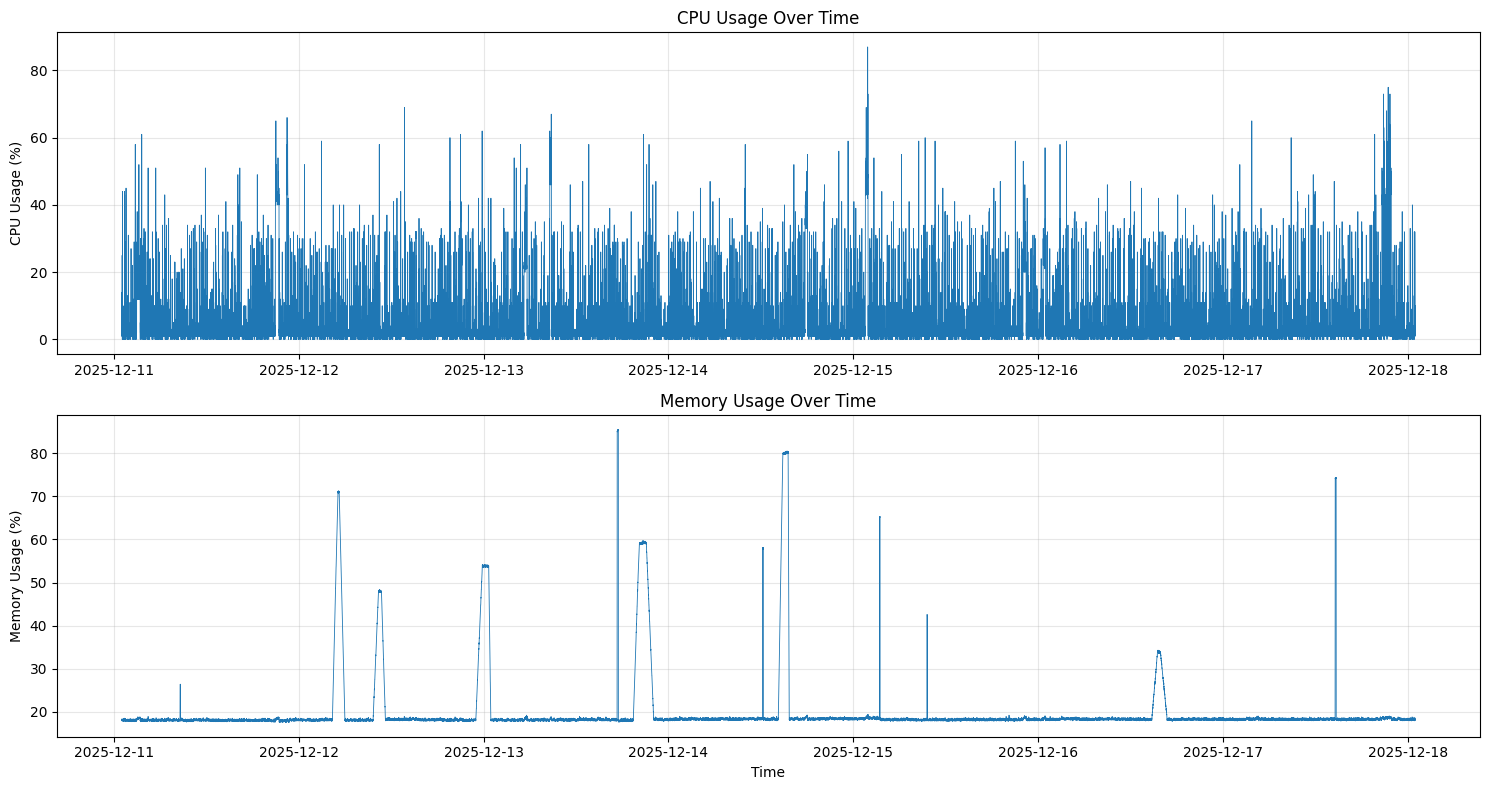

In [16]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

cpu_plot = cpu_df.copy()
memory_plot = memory_df.copy()

for df in [cpu_plot, memory_plot]:
    df["Time"] = pd.to_datetime(df["Time"], utc=True, errors="coerce")
    df["Value"] = pd.to_numeric(df["Value"], errors="coerce")
    df.loc[df["Value"] == -99999, "Value"] = np.nan

fig, axes = plt.subplots(2, 1, figsize=(15, 8))

axes[0].plot(cpu_plot["Time"], cpu_plot["Value"], linewidth=0.6)
axes[0].set_title("CPU Usage Over Time")
axes[0].set_ylabel("CPU Usage (%)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(memory_plot["Time"], memory_plot["Value"], linewidth=0.6)
axes[1].set_title("Memory Usage Over Time")
axes[1].set_ylabel("Memory Usage (%)")
axes[1].set_xlabel("Time")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
dataset_manifest = {
    "dataset_directory": EXTRACT_DIR,
    "csv_files": csv_files,
    "event_files": event_files,
    "cpu_file": cpu_path,
    "memory_file": memory_path,
    "cpu_shape": list(cpu_df.shape),
    "memory_shape": list(memory_df.shape),
}

save_json(dataset_manifest, "02_dataset_manifest.json")

print("Dataset manifest saved to Google Drive.")

Saved: /content/drive/MyDrive/PulseCheckAI/checkpoints/02_dataset_manifest.json
Dataset manifest saved to Google Drive.


In [18]:
# Load fresh copies of the original data
cpu_df = pd.read_csv(cpu_path)
memory_df = pd.read_csv(memory_path)

# Preserve original row order: event indices refer to these positions
cpu_time = pd.to_datetime(cpu_df["Time"], utc=True, errors="coerce")
memory_time = pd.to_datetime(memory_df["Time"], utc=True, errors="coerce")

cpu_values = pd.to_numeric(cpu_df["Value"], errors="coerce")
memory_values = pd.to_numeric(memory_df["Value"], errors="coerce")

print("CPU observations:", len(cpu_values))
print("Memory observations:", len(memory_values))
print("Timestamps match:", cpu_time.equals(memory_time))
print("CPU invalid sentinels:", (cpu_values == -99999).sum())
print("Memory invalid sentinels:", (memory_values == -99999).sum())

# We must verify alignment before combining the two metrics.
if len(cpu_df) != len(memory_df):
    raise ValueError("CPU and memory have different numbers of observations.")

if not cpu_time.equals(memory_time):
    raise ValueError(
        "CPU and memory timestamps do not align exactly. "
        "Stop here; we need to inspect the timestamps before combining them."
    )

if cpu_time.isna().any():
    raise ValueError("CPU timestamps contain invalid values.")

if memory_time.isna().any():
    raise ValueError("Memory timestamps contain invalid values.")

print("\nAlignment verified!")

CPU observations: 40320
Memory observations: 40320
Timestamps match: True
CPU invalid sentinels: 0
Memory invalid sentinels: 0

Alignment verified!


In [19]:
# Create a working dataset while preserving the original row positions
data = pd.DataFrame({
    "Time": cpu_time,
    "cpu_usage": cpu_values,
    "memory_usage": memory_values,
})

data["cpu_anomaly"] = 0
data["memory_anomaly"] = 0

# Reload event logs so this cell also works after a runtime restart
cpu_events = pd.read_csv(find_csv("event_logs_cpu.csv"))
memory_events = pd.read_csv(find_csv("event_logs_memory.csv"))

def apply_event_labels(data, events, label_column, metric_name):
    labeled_events = 0

    for _, event in events.iterrows():
        start = int(event["start_point"])
        end = int(event["end_point"])

        # Validate event positions against the original series
        if start < 0 or end < start or end >= len(data):
            raise ValueError(
                f"Invalid {metric_name} event interval: "
                f"start={start}, end={end}, rows={len(data)}"
            )

        # The documented end_point is inclusive
        data.loc[start:end, label_column] = 1
        labeled_events += 1

    print(f"{metric_name}: processed {labeled_events} events")

apply_event_labels(
    data, cpu_events, "cpu_anomaly", "CPU"
)

apply_event_labels(
    data, memory_events, "memory_anomaly", "Memory"
)

# Combined label: an event in either metric marks the observation
data["anomaly"] = (
    (data["cpu_anomaly"] == 1) |
    (data["memory_anomaly"] == 1)
).astype(int)

print("\nDataset shape:", data.shape)
print("\nCombined anomaly labels:")
print(data["anomaly"].value_counts())

print("\nCPU event-labeled observations:", data["cpu_anomaly"].sum())
print("Memory event-labeled observations:", data["memory_anomaly"].sum())
print("Combined event-labeled observations:", data["anomaly"].sum())

display(data.head())

CPU: processed 13 events
Memory: processed 12 events

Dataset shape: (40320, 6)

Combined anomaly labels:
anomaly
0    36303
1     4017
Name: count, dtype: int64

CPU event-labeled observations: 1192
Memory event-labeled observations: 2825
Combined event-labeled observations: 4017


,Time,cpu_usage,memory_usage,cpu_anomaly,memory_anomaly,anomaly
0,2025-12-11 01:00:00+00:00,2,18.1,0,0,0
1,2025-12-11 01:00:15+00:00,1,18.2,0,0,0
2,2025-12-11 01:00:30+00:00,2,18.1,0,0,0
3,2025-12-11 01:00:45+00:00,1,18.0,0,0,0
4,2025-12-11 01:01:00+00:00,2,18.0,0,0,0


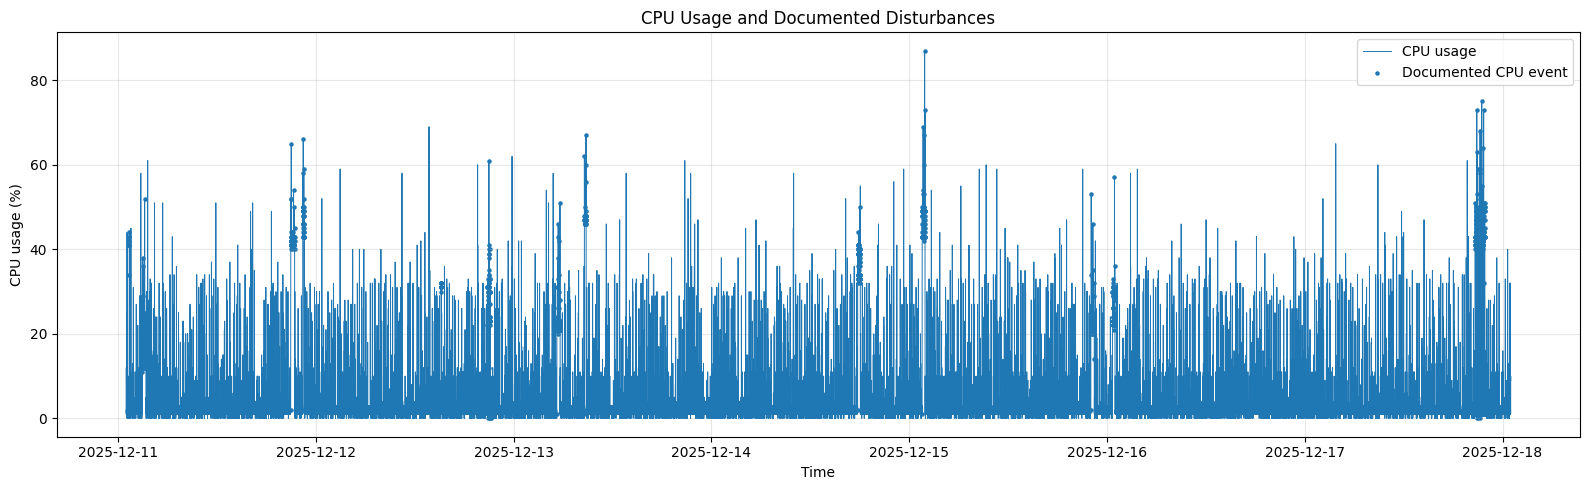

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 5))

plt.plot(
    data["Time"],
    data["cpu_usage"],
    linewidth=0.7,
    label="CPU usage"
)

cpu_mask = data["cpu_anomaly"] == 1

plt.scatter(
    data.loc[cpu_mask, "Time"],
    data.loc[cpu_mask, "cpu_usage"],
    s=5,
    label="Documented CPU event"
)

plt.title("CPU Usage and Documented Disturbances")
plt.xlabel("Time")
plt.ylabel("CPU usage (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

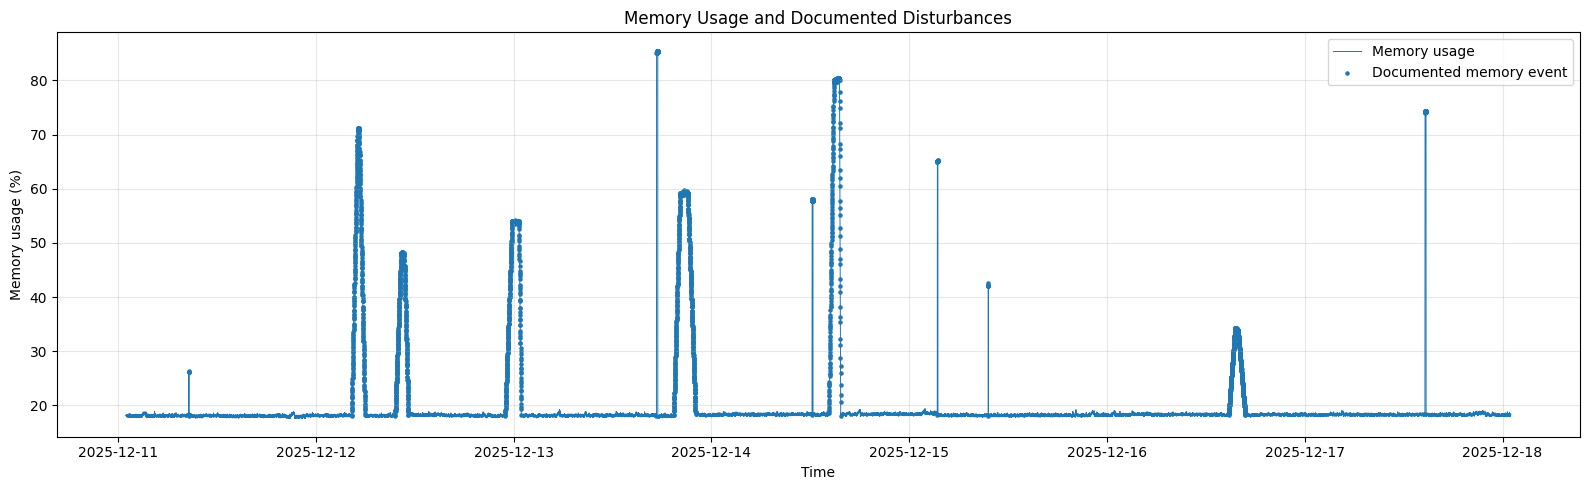

In [21]:
plt.figure(figsize=(16, 5))

plt.plot(
    data["Time"],
    data["memory_usage"],
    linewidth=0.7,
    label="Memory usage"
)

memory_mask = data["memory_anomaly"] == 1

plt.scatter(
    data.loc[memory_mask, "Time"],
    data.loc[memory_mask, "memory_usage"],
    s=5,
    label="Documented memory event"
)

plt.title("Memory Usage and Documented Disturbances")
plt.xlabel("Time")
plt.ylabel("Memory usage (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
# Save the working dataset
save_dataframe(data, "03_labeled_cpu_memory_data.csv")

# Save the event logs we used
save_dataframe(cpu_events, "cpu_events_used.csv")
save_dataframe(memory_events, "memory_events_used.csv")

label_summary = {
    "total_observations": len(data),
    "cpu_event_count": len(cpu_events),
    "memory_event_count": len(memory_events),
    "cpu_labeled_observations": int(data["cpu_anomaly"].sum()),
    "memory_labeled_observations": int(data["memory_anomaly"].sum()),
    "combined_labeled_observations": int(data["anomaly"].sum()),
    "normal_observations": int((data["anomaly"] == 0).sum()),
    "label_definition": (
        "An observation is labeled anomalous if it falls within "
        "a documented CPU or memory event interval."
    ),
}

save_json(label_summary, "03_label_summary.json")

print("\nLabeling stage saved successfully!")

Saved: /content/drive/MyDrive/PulseCheckAI/checkpoints/03_labeled_cpu_memory_data.csv
Saved: /content/drive/MyDrive/PulseCheckAI/checkpoints/cpu_events_used.csv
Saved: /content/drive/MyDrive/PulseCheckAI/checkpoints/memory_events_used.csv
Saved: /content/drive/MyDrive/PulseCheckAI/checkpoints/03_label_summary.json

Labeling stage saved successfully!


In [23]:
import numpy as np
import pandas as pd
import os

# Work on a copy of the labeled dataset
model_data = data.copy()

# Replace invalid sentinel values before feature engineering
for col in ["cpu_usage", "memory_usage"]:
    model_data[col] = pd.to_numeric(model_data[col], errors="coerce")
    model_data.loc[model_data[col] == -99999, col] = np.nan

# Create short-term rolling features.
# The dataset is sampled every 15 seconds:
# 4 rows = 1 minute; 20 rows = 5 minutes.
for col in ["cpu_usage", "memory_usage"]:
    model_data[f"{col}_change"] = model_data[col].diff()
    model_data[f"{col}_rolling_mean_1m"] = (
        model_data[col].rolling(window=4, min_periods=1).mean()
    )
    model_data[f"{col}_rolling_mean_5m"] = (
        model_data[col].rolling(window=20, min_periods=1).mean()
    )
    model_data[f"{col}_rolling_std_5m"] = (
        model_data[col].rolling(window=20, min_periods=2).std()
    )

FEATURES = [
    "cpu_usage",
    "memory_usage",
    "cpu_usage_change",
    "memory_usage_change",
    "cpu_usage_rolling_mean_1m",
    "memory_usage_rolling_mean_1m",
    "cpu_usage_rolling_mean_5m",
    "memory_usage_rolling_mean_5m",
    "cpu_usage_rolling_std_5m",
    "memory_usage_rolling_std_5m",
]

# Preserve labels and timestamps; don't silently discard observations.
model_data[FEATURES] = model_data[FEATURES].replace(
    [np.inf, -np.inf], np.nan
)

print("Feature count:", len(FEATURES))
print("Feature rows:", len(model_data))
print("\nMissing values per feature:")
print(model_data[FEATURES].isna().sum())

Feature count: 10
Feature rows: 40320

Missing values per feature:
cpu_usage                       0
memory_usage                    0
cpu_usage_change                1
memory_usage_change             1
cpu_usage_rolling_mean_1m       0
memory_usage_rolling_mean_1m    0
cpu_usage_rolling_mean_5m       0
memory_usage_rolling_mean_5m    0
cpu_usage_rolling_std_5m        1
memory_usage_rolling_std_5m     1
dtype: int64


In [24]:
split_index = int(len(model_data) * 0.70)

train_data = model_data.iloc[:split_index].copy()
test_data = model_data.iloc[split_index:].copy()

print("Training period:")
print(train_data["Time"].min(), "to", train_data["Time"].max())

print("\nTesting period:")
print(test_data["Time"].min(), "to", test_data["Time"].max())

print("\nTraining observations:", len(train_data))
print("Testing observations:", len(test_data))

print("\nTraining anomaly labels:")
print(train_data["anomaly"].value_counts())

print("\nTesting anomaly labels:")
print(test_data["anomaly"].value_counts())

Training period:
2025-12-11 01:00:00+00:00 to 2025-12-15 22:35:45+00:00

Testing period:
2025-12-15 22:36:00+00:00 to 2025-12-18 00:59:45+00:00

Training observations: 28224
Testing observations: 12096

Training anomaly labels:
anomaly
0    25093
1     3131
Name: count, dtype: int64

Testing anomaly labels:
anomaly
0    11210
1      886
Name: count, dtype: int64


In [25]:
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Use only normal observations for fitting.
# Exclude invalid feature rows from the training data.
normal_train = train_data.loc[train_data["anomaly"] == 0]

valid_train = normal_train[FEATURES].dropna()

if len(valid_train) == 0:
    raise ValueError("No valid normal training observations were found.")

# This initial contamination setting is a modeling parameter,
# not an assertion about the true anomaly rate.
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("detector", IsolationForest(
        n_estimators=200,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(valid_train)

print("Isolation Forest trained!")
print("Normal training rows used:", len(valid_train))

Isolation Forest trained!
Normal training rows used: 25092


In [26]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# Only evaluate rows with valid features
test_valid_mask = test_data[FEATURES].notna().all(axis=1)

test_valid = test_data.loc[test_valid_mask].copy()

X_test = test_valid[FEATURES]
y_test = test_valid["anomaly"].astype(int)

# Isolation Forest returns -1 for anomalies and 1 for normal observations
predictions = model.predict(X_test)
y_pred = (predictions == -1).astype(int)

print("Classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Documented disturbance"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test, y_pred), 4
))

Classification report:
                        precision    recall  f1-score   support

                Normal       1.00      0.94      0.97     11210
Documented disturbance       0.57      0.99      0.73       886

              accuracy                           0.95     12096
             macro avg       0.79      0.97      0.85     12096
          weighted avg       0.97      0.95      0.95     12096

Confusion matrix:
[[10557   653]
 [    9   877]]
Precision: 0.5732
Recall: 0.9898
F1-score: 0.726
Balanced accuracy: 0.9658


In [27]:
baseline_pred = (
    (test_valid["cpu_usage"] > 80) |
    (test_valid["memory_usage"] > 80)
).astype(int)

print("Simple threshold baseline")
print("-------------------------")
print("Precision:", round(
    precision_score(y_test, baseline_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, baseline_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, baseline_pred, zero_division=0), 4
))

print("\nIsolation Forest")
print("----------------")
print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))

Simple threshold baseline
-------------------------
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Isolation Forest
----------------
Precision: 0.5732
Recall: 0.9898
F1-score: 0.726


In [28]:
import json
import joblib

model_path = os.path.join(MODEL_DIR, "pulsecheck_isolation_forest.joblib")
joblib.dump(model, model_path)

evaluation = {
    "model": "IsolationForest",
    "features": FEATURES,
    "train_rows_total": int(len(train_data)),
    "train_normal_rows_used": int(len(valid_train)),
    "test_rows_evaluated": int(len(test_valid)),
    "test_anomaly_rows": int(y_test.sum()),
    "test_normal_rows": int((y_test == 0).sum()),
    "precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "f1_score": float(f1_score(y_test, y_pred, zero_division=0)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, y_pred)),
    "confusion_matrix": confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).tolist(),
    "baseline_precision": float(
        precision_score(y_test, baseline_pred, zero_division=0)
    ),
    "baseline_recall": float(
        recall_score(y_test, baseline_pred, zero_division=0)
    ),
    "baseline_f1_score": float(
        f1_score(y_test, baseline_pred, zero_division=0)
    ),
}

results_path = os.path.join(RESULTS_DIR, "model_evaluation.json")

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(evaluation, f, indent=4)

print("Model saved:", model_path)
print("Evaluation saved:", results_path)
print("\nSaved evaluation summary:")
print(json.dumps(evaluation, indent=2))

Model saved: /content/drive/MyDrive/PulseCheckAI/models/pulsecheck_isolation_forest.joblib
Evaluation saved: /content/drive/MyDrive/PulseCheckAI/results/model_evaluation.json

Saved evaluation summary:
{
  "model": "IsolationForest",
  "features": [
    "cpu_usage",
    "memory_usage",
    "cpu_usage_change",
    "memory_usage_change",
    "cpu_usage_rolling_mean_1m",
    "memory_usage_rolling_mean_1m",
    "cpu_usage_rolling_mean_5m",
    "memory_usage_rolling_mean_5m",
    "cpu_usage_rolling_std_5m",
    "memory_usage_rolling_std_5m"
  ],
  "train_rows_total": 28224,
  "train_normal_rows_used": 25092,
  "test_rows_evaluated": 12096,
  "test_anomaly_rows": 886,
  "test_normal_rows": 11210,
  "precision": 0.5732026143790849,
  "recall": 0.989841986455982,
  "f1_score": 0.7259933774834437,
  "balanced_accuracy": 0.9657952126749134,
  "confusion_matrix": [
    [
      10557,
      653
    ],
    [
      9,
      877
    ]
  ],
  "baseline_precision": 0.0,
  "baseline_recall": 0.0,
  "bas

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print(f"\nTrue negatives:  {tn:,}")
print(f"False positives: {fp:,}")
print(f"False negatives: {fn:,}")
print(f"True positives:  {tp:,}")

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Disturbance"]
).plot()

plt.title("PulseCheck AI — Test Results")
plt.tight_layout()
plt.show()

In [30]:
model_config = {
    "model_name": "PulseCheck AI",
    "algorithm": "IsolationForest",
    "model_file": "pulsecheck_isolation_forest.joblib",
    "features": FEATURES,
    "sampling_interval_seconds": 15,
    "rolling_window_1m_samples": 4,
    "rolling_window_5m_samples": 20,
    "anomaly_prediction": -1,
    "normal_prediction": 1,
    "training_dataset": "OSMetrics",
    "label_definition": (
        "Documented CPU or memory disturbance intervals"
    ),
    "limitations": [
        "Trained on a public performance time-series dataset",
        "Dataset anomalies are not confirmed hardware failures",
        "Real laptop performance may differ from the training data"
    ]
}

config_path = os.path.join(MODEL_DIR, "pulsecheck_config.json")

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(model_config, f, indent=4)

print("Model:", model_path)
print("Configuration:", config_path)
print("Saved successfully!")

Model: /content/drive/MyDrive/PulseCheckAI/models/pulsecheck_isolation_forest.joblib
Configuration: /content/drive/MyDrive/PulseCheckAI/models/pulsecheck_config.json
Saved successfully!


In [31]:
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

# Chronological 60/20/20 split
n = len(model_data)
train_end = int(n * 0.60)
val_end = int(n * 0.80)

train = model_data.iloc[:train_end].copy()
val = model_data.iloc[train_end:val_end].copy()
test = model_data.iloc[val_end:].copy()

# Train on normal observations only
normal_train = train.loc[train["anomaly"] == 0]
X_train = normal_train[FEATURES].dropna()

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("detector", IsolationForest(
        n_estimators=200,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train)

print("Training observations:", len(X_train))
print("Validation observations:", len(val))
print("Test observations:", len(test))

Training observations: 21169
Validation observations: 8064
Test observations: 8064


In [32]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import numpy as np
import pandas as pd

# Keep only rows with valid feature values
val_valid = val.loc[val[FEATURES].notna().all(axis=1)].copy()

X_val = val_valid[FEATURES]
y_val = val_valid["anomaly"].astype(int).to_numpy()

# Isolation Forest: lower decision_function values are more anomalous.
# Negating the score means higher values indicate greater anomaly likelihood.
val_scores = -model.decision_function(X_val)

# Evaluate several thresholds using validation data only.
thresholds = np.unique(
    np.quantile(val_scores, np.linspace(0.50, 0.995, 200))
)

results = []

for threshold in thresholds:
    pred = (val_scores >= threshold).astype(int)

    precision = precision_score(y_val, pred, zero_division=0)
    recall = recall_score(y_val, pred, zero_division=0)
    f1 = f1_score(y_val, pred, zero_division=0)

    results.append({
        "threshold": float(threshold),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "alerts": int(pred.sum())
    })

threshold_results = pd.DataFrame(results)

# Prefer thresholds that achieve the precision target.
target_precision = 0.80
acceptable = threshold_results[
    threshold_results["precision"] >= target_precision
]

if not acceptable.empty:
    # Maximize recall; use F1 to break ties.
    best = acceptable.sort_values(
        ["recall", "f1"],
        ascending=False
    ).iloc[0]

    print(f"Found a threshold meeting {target_precision:.0%} precision.")
else:
    # If the target is unattainable, maximize F1 instead.
    best = threshold_results.sort_values(
        ["f1", "precision"],
        ascending=False
    ).iloc[0]

    print(
        f"No tested threshold reached {target_precision:.0%} precision. "
        "Showing the best F1 threshold instead."
    )

best_threshold = float(best["threshold"])

print("\nSelected validation threshold:")
print(best)

Found a threshold meeting 80% precision.

Selected validation threshold:
threshold      0.100004
precision      0.804094
recall         0.830816
f1             0.817236
alerts       342.000000
Name: 184, dtype: float64


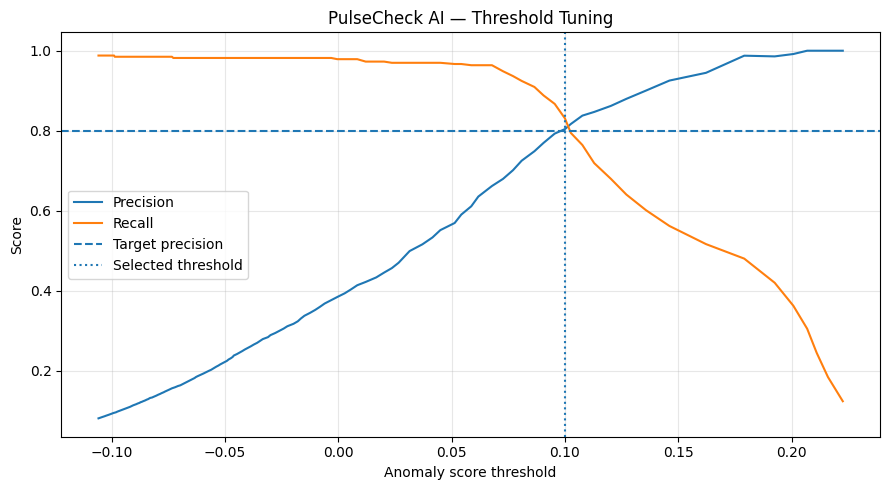

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    label="Precision"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    label="Recall"
)

plt.axhline(
    target_precision,
    linestyle="--",
    label="Target precision"
)

plt.axvline(
    best_threshold,
    linestyle=":",
    label="Selected threshold"
)

plt.xlabel("Anomaly score threshold")
plt.ylabel("Score")
plt.title("PulseCheck AI — Threshold Tuning")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
test_valid = test.loc[test[FEATURES].notna().all(axis=1)].copy()

X_test = test_valid[FEATURES]
y_test = test_valid["anomaly"].astype(int).to_numpy()

test_scores = -model.decision_function(X_test)
test_pred = (test_scores >= best_threshold).astype(int)

print("Final test-set results")
print("=" * 40)

print(classification_report(
    y_test,
    test_pred,
    labels=[0, 1],
    target_names=["Normal", "Documented disturbance"],
    zero_division=0
))

cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
print("Confusion matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print(f"\nFalse alarms: {fp:,}")
print(f"Missed disturbances: {fn:,}")
print(f"Total alerts: {fp + tp:,}")
print(f"Precision: {precision_score(y_test, test_pred, zero_division=0):.3f}")
print(f"Recall: {recall_score(y_test, test_pred, zero_division=0):.3f}")
print(f"F1-score: {f1_score(y_test, test_pred, zero_division=0):.3f}")

Final test-set results
                        precision    recall  f1-score   support

                Normal       0.98      0.99      0.99      7400
Documented disturbance       0.87      0.81      0.84       664

              accuracy                           0.97      8064
             macro avg       0.93      0.90      0.91      8064
          weighted avg       0.97      0.97      0.97      8064

Confusion matrix:
[[7319   81]
 [ 126  538]]

False alarms: 81
Missed disturbances: 126
Total alerts: 619
Precision: 0.869
Recall: 0.810
F1-score: 0.839


In [35]:
import os
import json
import joblib

MODEL_DIR = "/content/drive/MyDrive/PulseCheckAI/models"
RESULTS_DIR = "/content/drive/MyDrive/PulseCheckAI/results"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

model_path = os.path.join(
    MODEL_DIR,
    "pulsecheck_isolation_forest_tuned.joblib"
)

joblib.dump(model, model_path)

config = {
    "model_name": "PulseCheck AI",
    "algorithm": "IsolationForest",
    "features": FEATURES,
    "anomaly_score_definition": "-model.decision_function(X)",
    "anomaly_threshold": best_threshold,
    "target_validation_precision": target_precision,
    "selected_validation_precision": float(best["precision"]),
    "selected_validation_recall": float(best["recall"]),
    "sampling_interval_seconds": 15,
    "rolling_window_1m_samples": 4,
    "rolling_window_5m_samples": 20,
    "label_definition": (
        "Documented CPU or memory disturbance intervals"
    )
}

config_path = os.path.join(
    MODEL_DIR,
    "pulsecheck_tuned_config.json"
)

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)

evaluation = {
    "threshold": best_threshold,
    "precision": float(precision_score(y_test, test_pred, zero_division=0)),
    "recall": float(recall_score(y_test, test_pred, zero_division=0)),
    "f1_score": float(f1_score(y_test, test_pred, zero_division=0)),
    "confusion_matrix": cm.tolist(),
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp)
}

with open(
    os.path.join(RESULTS_DIR, "tuned_model_evaluation.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(evaluation, f, indent=4)

print("Tuned model and threshold saved to Google Drive.")

Tuned model and threshold saved to Google Drive.


In [36]:
import os
import json
import joblib

print("Model exists:", os.path.exists(model_path))
print("Configuration exists:", os.path.exists(config_path))

saved_model = joblib.load(model_path)

with open(config_path, "r", encoding="utf-8") as f:
    saved_config = json.load(f)

print("\nSaved threshold:", saved_config["anomaly_threshold"])
print("Saved features:", saved_config["features"])

Model exists: True
Configuration exists: True

Saved threshold: 0.10000384221612314
Saved features: ['cpu_usage', 'memory_usage', 'cpu_usage_change', 'memory_usage_change', 'cpu_usage_rolling_mean_1m', 'memory_usage_rolling_mean_1m', 'cpu_usage_rolling_mean_5m', 'memory_usage_rolling_mean_5m', 'cpu_usage_rolling_std_5m', 'memory_usage_rolling_std_5m']


In [37]:
import sklearn
import joblib

print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)

scikit-learn: 1.6.1
joblib: 1.6.0
